# 02 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.


In [50]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [51]:
from pathlib import Path
import sys

import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    build_yearly_si_dataset,
    rank_future_high_interest_pairs,
)
from amr.si import (
    build_yearly_category_counts,
    plot_yearly_category_driver_counts,
    plot_yearly_si_pair,
    summarize_si_change_drivers,
)



## Configuration


In [52]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "assets").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT

YEARLY_SCREENED_PATH = DATA_DIR / "yearly_amr_screened_pairs.parquet"
UNIFIED_DECISIONS_PATH = DATA_DIR / "yearly_amr_unified_decisions.parquet"
PATHOGEN_BG_PATH = DATA_DIR / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = DATA_DIR / "antibiotic_tiab_counts.parquet"

YEARLY_SI_PATH = DATA_DIR / "yearly_si.parquet"
RANK_OUTPUT_PATH = DATA_DIR / "yearly_si_ranked_future.parquet"
INTERESTING_OUTPUT_PATH = DATA_DIR / "yearly_si_ranked_future_interesting.parquet"
DRIVER_OUTPUT_PATH = DATA_DIR / "yearly_si_driver_explanations.parquet"
INTERESTING_PLOT_DIR = DATA_DIR / "interesting_yearly_si_pngs"
DRIVER_PLOT_DIR = DATA_DIR / "interesting_yearly_si_driver_pngs"

FIT_START_YEAR = 2020
FIT_END_YEAR = 2023
NUM_FUTURE_YEARS = 2

MIN_CURRENT_PREDICTED_COUNT = 1
MIN_FUTURE_PREDICTED_COUNT = 1
MIN_SI_CHANGE = 0.02
MIN_POST_FIT_OBSERVED_YEARS = 1
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = 750.0
FALLBACK_TOP_N = 10

CATEGORY_INCLUDE_DECISIONS = ("yes", "uncertain")
DRIVER_LOOKBACK_YEARS = 5
MAX_DRIVER_PLOTS = 25



## Load Canonical Inputs


In [53]:
yearly_screened_df = pd.read_parquet(YEARLY_SCREENED_PATH)
pathogen_bg_df = pd.read_parquet(PATHOGEN_BG_PATH)
antibiotic_bg_df = pd.read_parquet(ANTIBIOTIC_BG_PATH)

driver_required_cols = {
    "pathogen",
    "antibiotic",
    "year",
    "unified_decision",
    "amr_primary_category",
    "amr_pair_centrality",
    "amr_needs_manual_review",
}
unified_decisions_df = pd.DataFrame()
if UNIFIED_DECISIONS_PATH.exists():
    candidate_unified_df = pd.read_parquet(UNIFIED_DECISIONS_PATH)
    missing_driver_cols = driver_required_cols - set(candidate_unified_df.columns)
    if missing_driver_cols:
        print(
            "Skipping SI driver classification analysis because "
            f"{UNIFIED_DECISIONS_PATH} is missing columns: {sorted(missing_driver_cols)}"
        )
    else:
        unified_decisions_df = candidate_unified_df
else:
    print(
        "Skipping SI driver classification analysis because "
        f"{UNIFIED_DECISIONS_PATH} was not found."
    )

print(f"yearly_screened rows: {len(yearly_screened_df):,}")
print(f"pathogen bg rows: {len(pathogen_bg_df):,}")
print(f"antibiotic bg rows: {len(antibiotic_bg_df):,}")
print(f"unified decision rows available for driver analysis: {len(unified_decisions_df):,}")


yearly_screened rows: 72
pathogen bg rows: 28
antibiotic bg rows: 35
unified decision rows available for driver analysis: 1,540


## Build Yearly SI Dataset


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [54]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_df,
    pathogen_bg_df,
    antibiotic_bg_df,
    output_path=YEARLY_SI_PATH,
)

print(f"SI rows: {len(si_df):,}")
print(f"SI pairs: {si_df[['pathogen','antibiotic']].drop_duplicates().shape[0]:,}")
si_df.head(10)


SI rows: 72
SI pairs: 13


,pathogen,antibiotic,year,count,pmids,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Clostridioides difficile,Ampicillin,2024,1,[38345622],955,1149,0.301030,2.980458,3.060698,0.705815,4.079435,-0.404785
1,Klebsiella pneumoniae,Amikacin,2020,37,"[31525541, 31627023, 31838661, 31869560, 31918...",1848,560,1.579784,3.266937,2.748963,1.375021,22.714899,0.204762
2,Klebsiella pneumoniae,Amikacin,2021,39,"[32247662, 33442721, 33516275, 33590977, 33614...",2149,609,1.602060,3.332438,2.785330,1.409065,24.648677,0.192995
3,Klebsiella pneumoniae,Amikacin,2022,41,"[32102584, 34330663, 34742638, 34851744, 35033...",2402,599,1.623249,3.380754,2.778151,1.419802,25.290682,0.203447
4,Klebsiella pneumoniae,Amikacin,2023,45,"[36269193, 36318402, 36671365, 36814229, 36818...",2278,600,1.662758,3.357744,2.778874,1.413549,24.914874,0.249209
5,Klebsiella pneumoniae,Amikacin,2024,24,"[37951832, 38287256, 38296537, 38381147, 38389...",2595,600,1.397940,3.414305,2.778874,1.429671,25.894949,-0.031731
6,Klebsiella pneumoniae,Amikacin,2025,73,"[39471310, 39667638, 39670759, 39754049, 39799...",3262,681,1.869232,3.513617,2.833784,1.481190,29.282405,0.388041
7,Klebsiella pneumoniae,Amikacin,2026,20,"[41296999, 41517741, 41555234, 41580656, 41594...",1335,261,1.322219,3.125806,2.418301,1.195013,14.667971,0.127207
8,Klebsiella pneumoniae,Amoxicillin,2020,17,"[31608743, 31927517, 32156029, 32190999, 32219...",1848,1138,1.255273,3.266937,3.056524,1.418387,25.205200,-0.163115
9,Klebsiella pneumoniae,Amoxicillin,2021,23,"[33590977, 33622283, 33662642, 33670224, 33673...",2149,1181,1.380211,3.332438,3.072617,1.443861,26.788238,-0.063650


## Rank Reliable Future High-Interest Pairs


In [55]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

interesting_df[
    [
        "pathogen",
        "antibiotic",
        "interest_score",
        "si_change",
        "current_predicted_count",
        "future_predicted_count",
        "post_fit_si_abs_pct_error_mean",
    ]
].head(30)


[1/13] ranking Clostridioides difficile vs Ampicillin
[2/13] ranking Klebsiella pneumoniae vs Amikacin
[3/13] ranking Klebsiella pneumoniae vs Amoxicillin
[4/13] ranking Klebsiella pneumoniae vs Amoxicillin/clavulanic-acid
[5/13] ranking Klebsiella pneumoniae vs Ampicillin
[6/13] ranking Klebsiella pneumoniae vs Ampicillin/sulbactam
[7/13] ranking Mycobacterium tuberculosis vs Amikacin
[8/13] ranking Mycobacterium tuberculosis vs Ampicillin
[9/13] ranking Salmonella enterica vs Amikacin
[10/13] ranking Salmonella enterica vs Amoxicillin
[11/13] ranking Salmonella enterica vs Amoxicillin/clavulanic-acid
[12/13] ranking Salmonella enterica vs Ampicillin
[13/13] ranking Salmonella enterica vs Ampicillin/sulbactam


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Amoxicillin/clavulanic-acid,0.067866,0.153798,20.371073,38.203375,330.763025
1,Salmonella enterica,Ampicillin/sulbactam,0.063336,0.163328,2.821092,5.280927,191.703417
2,Klebsiella pneumoniae,Ampicillin,0.050985,0.140620,60.192081,100.788534,650.664112
3,Klebsiella pneumoniae,Amoxicillin,0.024295,0.073669,31.803163,46.952693,670.465952
4,Salmonella enterica,Amoxicillin/clavulanic-acid,0.014712,0.035282,4.505845,6.265006,170.303045


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [56]:
category_counts_df = build_yearly_category_counts(
    unified_decisions_df,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
)
driver_summary_df = summarize_si_change_drivers(
    interesting_df,
    unified_decisions_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
)

if driver_summary_df.empty:
    interesting_with_drivers_df = interesting_df.copy()
    print("No SI driver classification summaries were produced.")
else:
    interesting_with_drivers_df = interesting_df.merge(
        driver_summary_df,
        on=["pathogen", "antibiotic"],
        how="left",
    )
    interesting_with_drivers_df.to_parquet(DRIVER_OUTPUT_PATH, index=False)
    print(f"Saved SI driver explanations to {DRIVER_OUTPUT_PATH}")

driver_display_cols = [
    "pathogen",
    "antibiotic",
    "interest_score",
    "si_change",
    "current_predicted_count",
    "future_predicted_count",
    "driver_recent_total",
    "driver_count_change",
    "driver_dominant_category",
    "driver_fastest_growing_category",
    "driver_weak_signal_share",
    "driver_manual_review_share",
]
available_driver_cols = [col for col in driver_display_cols if col in interesting_with_drivers_df.columns]
interesting_with_drivers_df[available_driver_cols].head(30)


Saved SI driver explanations to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_manual_review_share
0,Klebsiella pneumoniae,Amoxicillin/clavulanic-acid,0.067866,0.153798,20.371073,38.203375,55,55,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.709091
1,Salmonella enterica,Ampicillin/sulbactam,0.063336,0.163328,2.821092,5.280927,7,7,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.714286
2,Klebsiella pneumoniae,Ampicillin,0.050985,0.140620,60.192081,100.788534,172,172,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.779070
3,Klebsiella pneumoniae,Amoxicillin,0.024295,0.073669,31.803163,46.952693,97,97,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.876289
4,Salmonella enterica,Amoxicillin/clavulanic-acid,0.014712,0.035282,4.505845,6.265006,16,16,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.937500


## Plot Category Driver Curves


Saved 5 category driver plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/interesting_yearly_si_driver_pngs


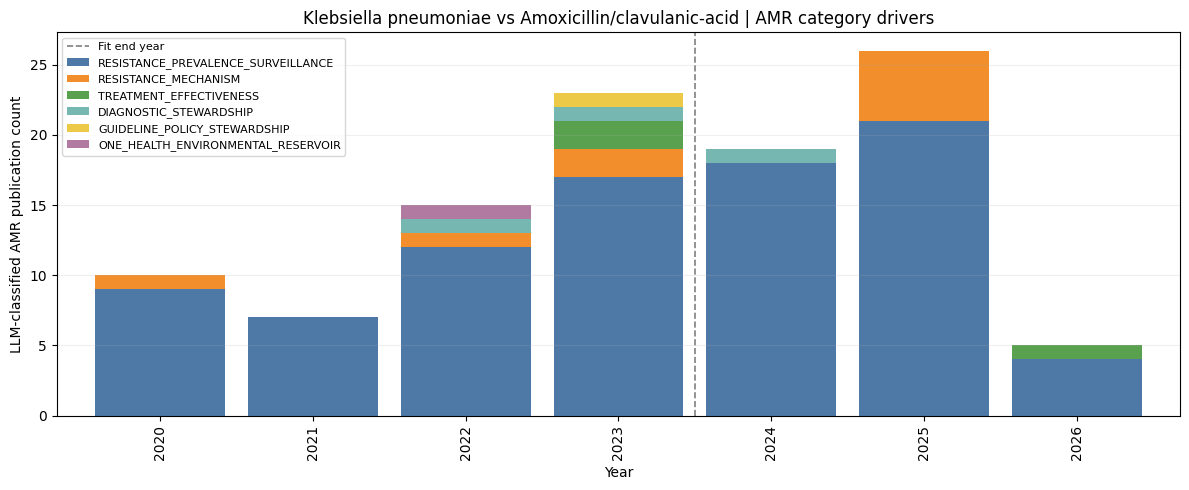

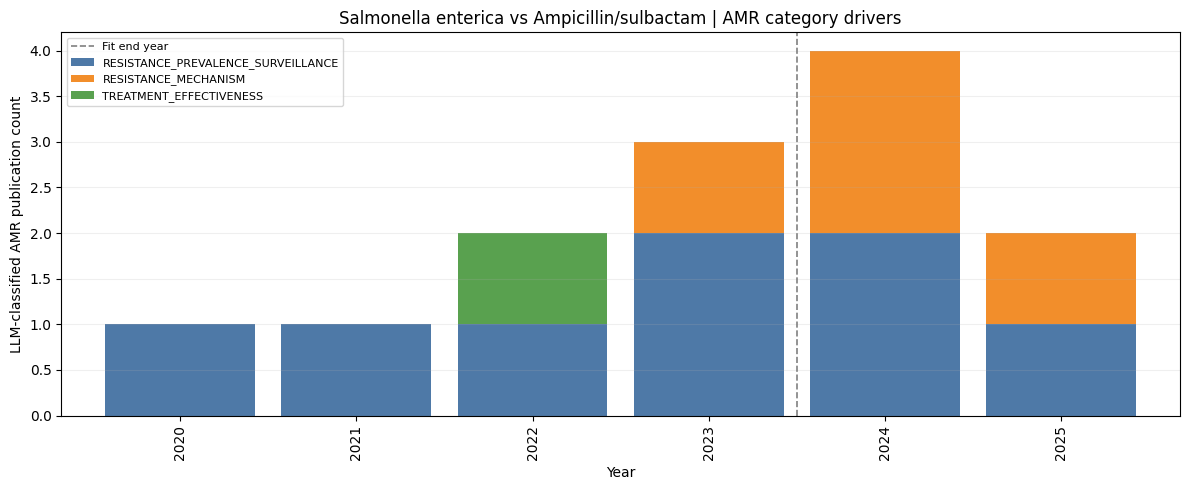

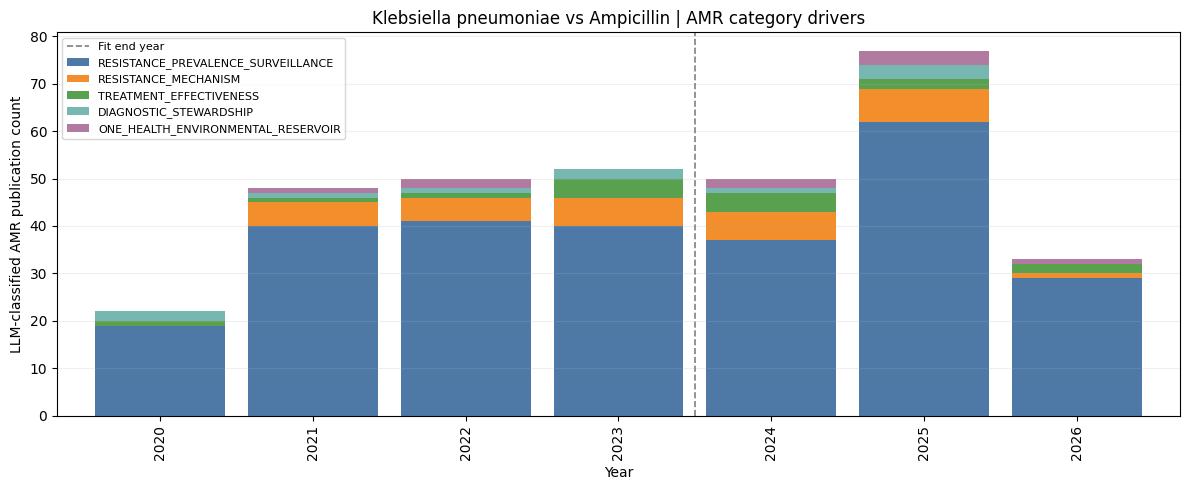

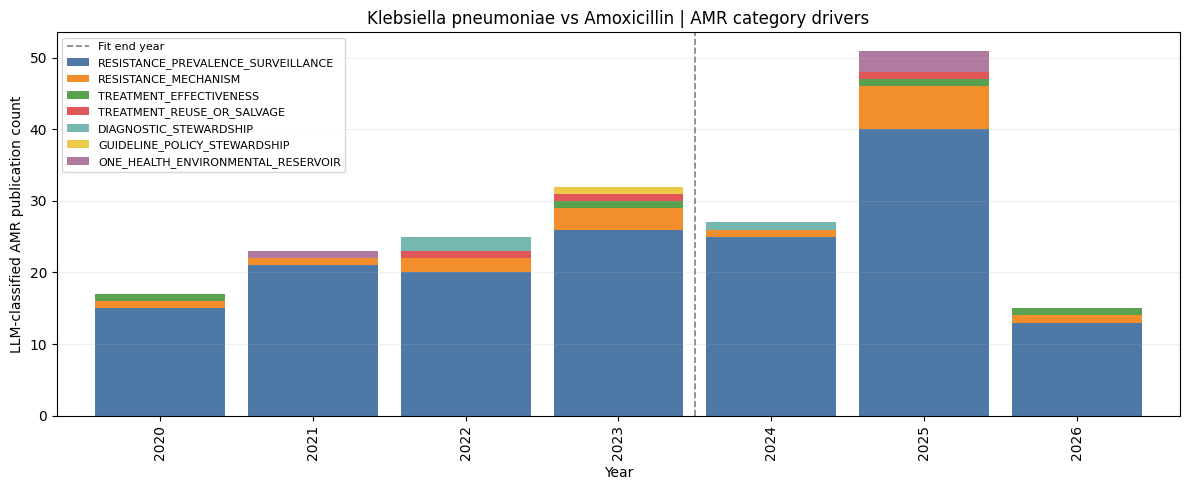

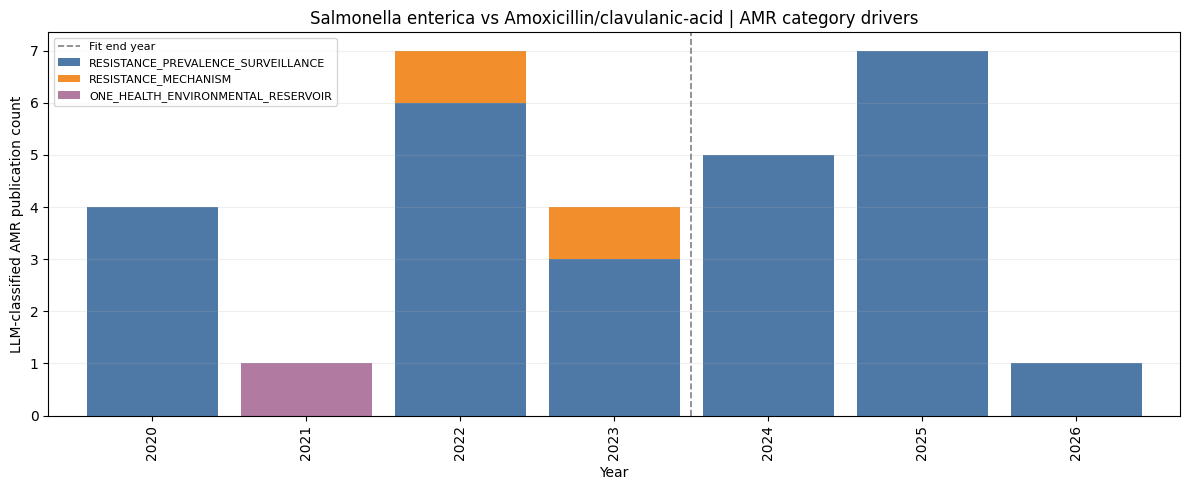

In [57]:
DRIVER_PLOT_DIR.mkdir(parents=True, exist_ok=True)
saved_driver_plots = 0

if category_counts_df.empty:
    print("No category count curves available to plot.")
else:
    for row in interesting_df.head(MAX_DRIVER_PLOTS).itertuples(index=False):
        try:
            result = plot_yearly_category_driver_counts(
                category_counts_df=category_counts_df,
                pathogen=row.pathogen,
                antibiotic=row.antibiotic,
                fit_end_year=FIT_END_YEAR,
            )
        except ValueError:
            continue
        pathogen_slug = str(row.pathogen).replace("/", "_").replace(" ", "_")
        antibiotic_slug = str(row.antibiotic).replace("/", "_").replace(" ", "_")
        out_path = DRIVER_PLOT_DIR / f"{pathogen_slug}__{antibiotic_slug}__drivers.png"
        result["figure"].savefig(out_path, dpi=200, bbox_inches="tight")
        saved_driver_plots += 1

    print(f"Saved {saved_driver_plots} category driver plots to {DRIVER_PLOT_DIR}")


## Plot Top Interesting Pairs


Saved 5 plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/interesting_yearly_si_pngs


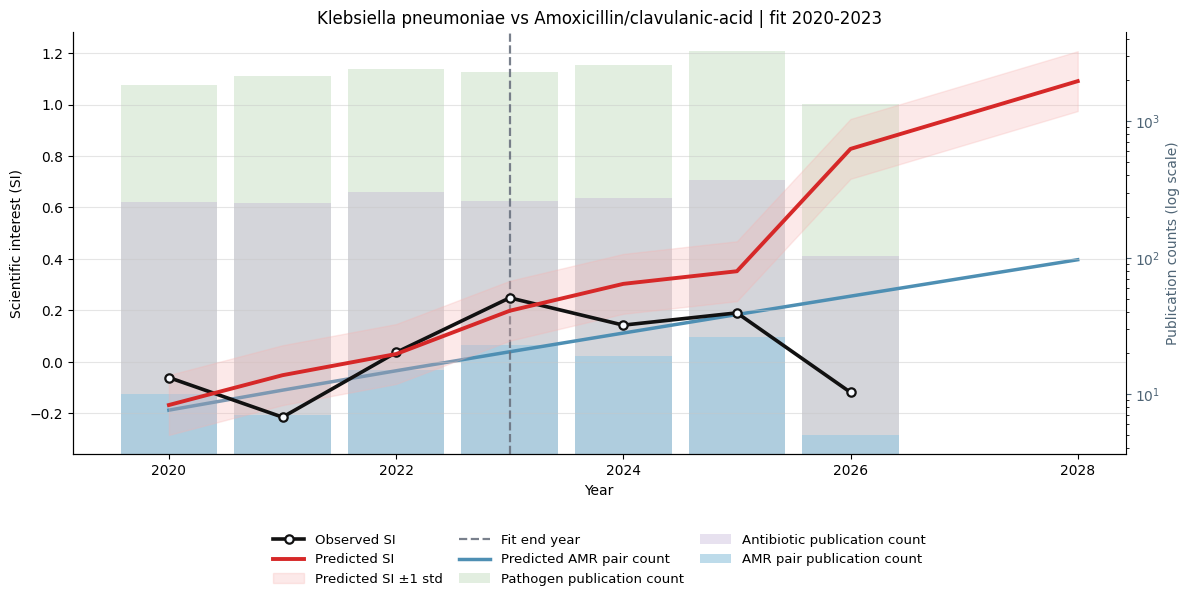

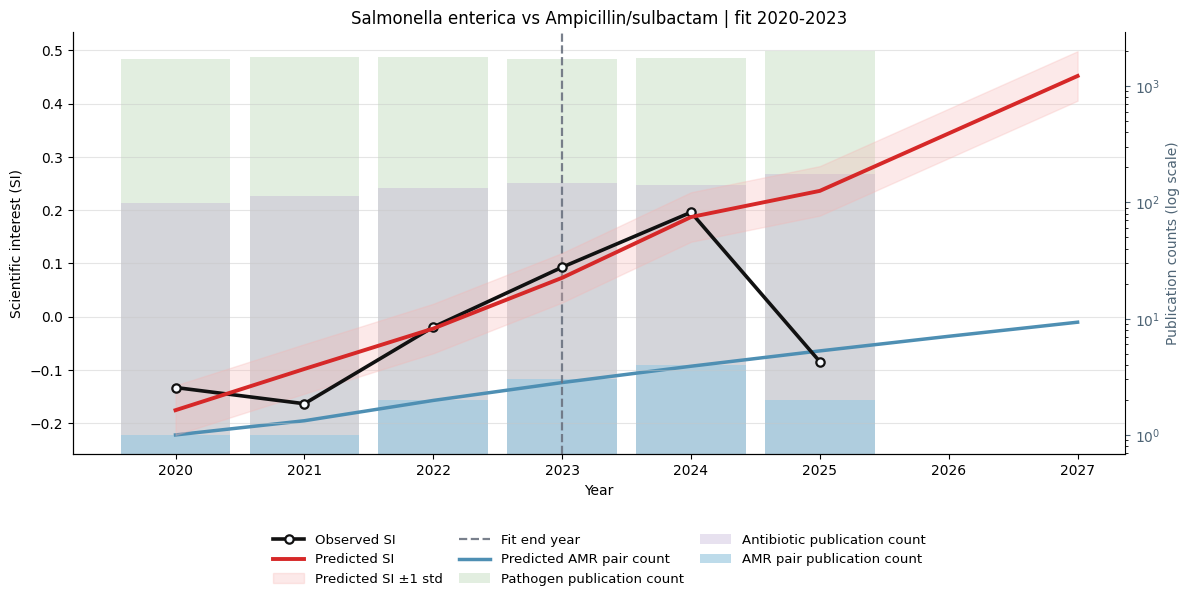

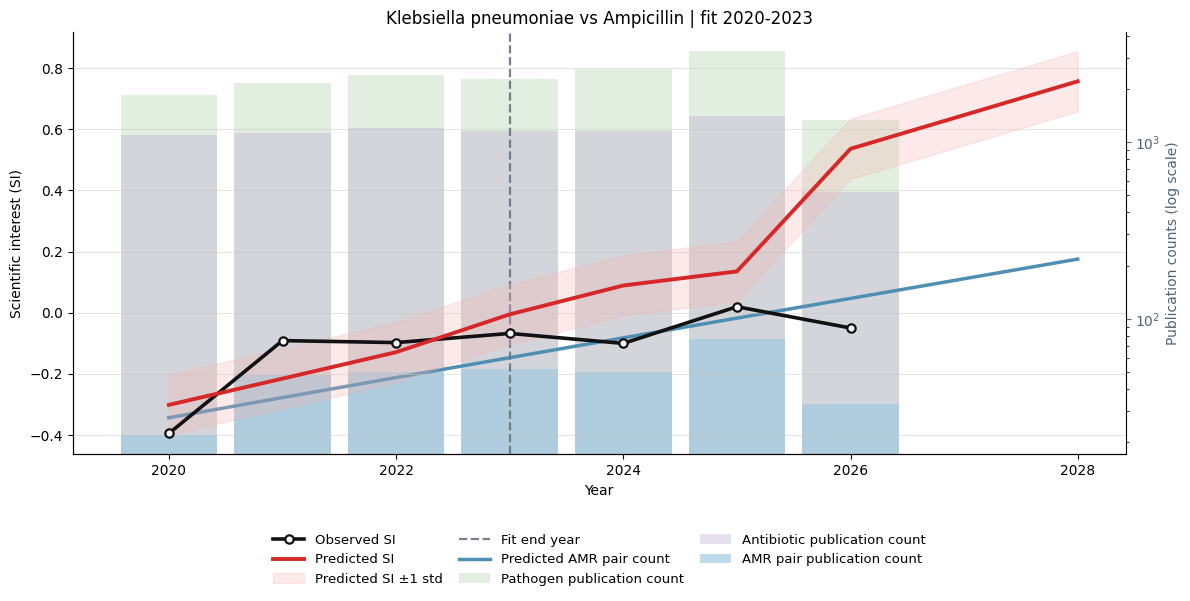

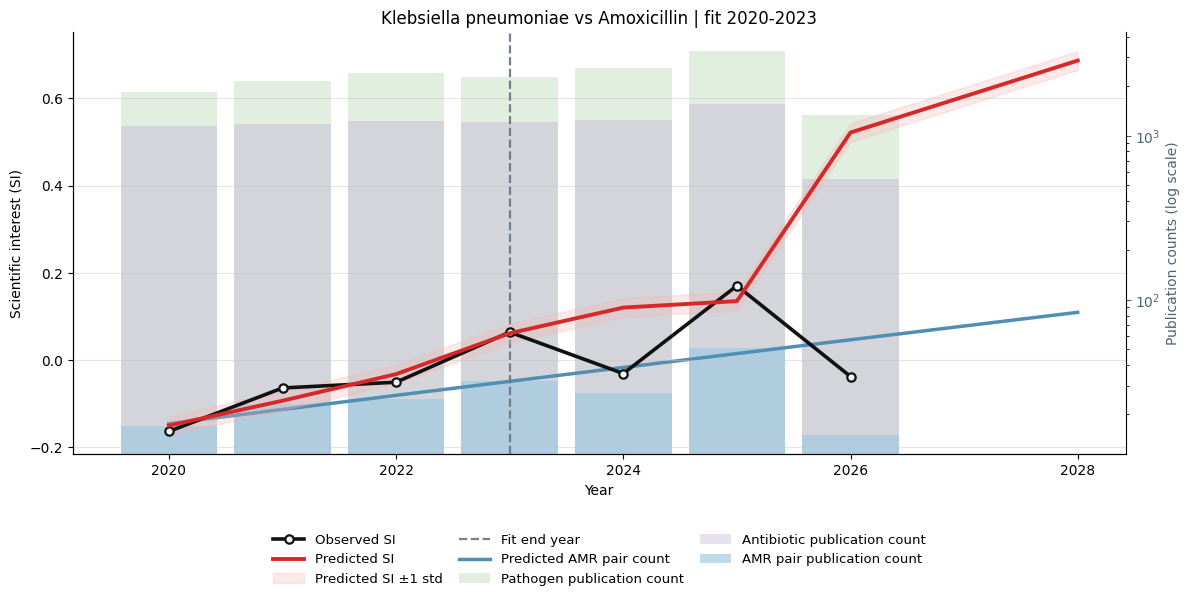

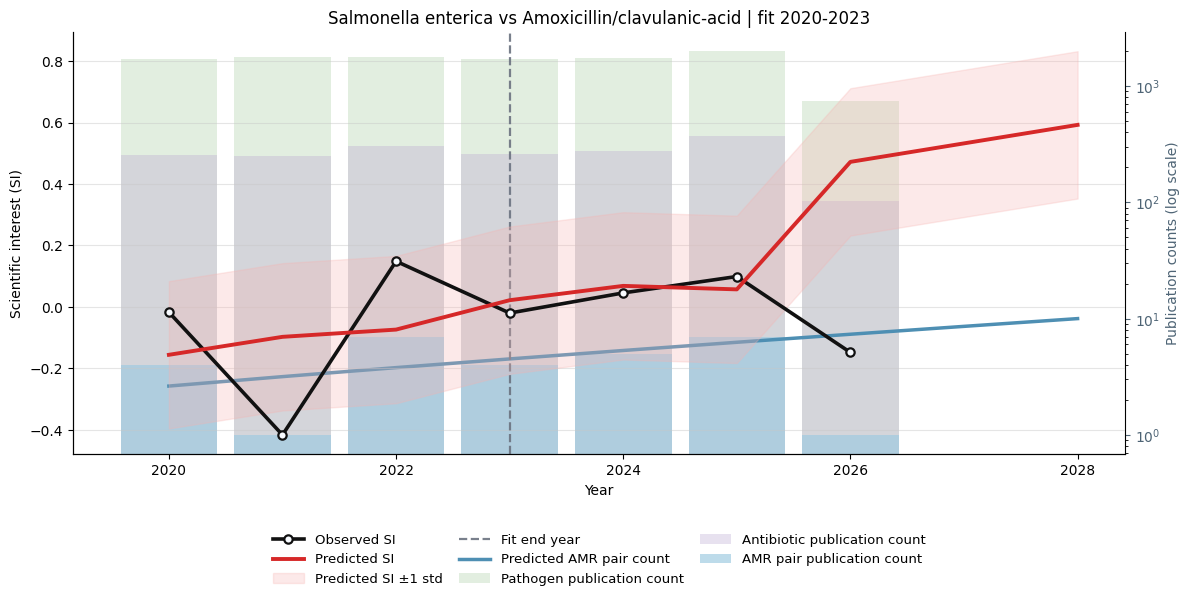

In [58]:
INTERESTING_PLOT_DIR.mkdir(parents=True, exist_ok=True)

for row in interesting_df.head(25).itertuples(index=False):
    result = plot_yearly_si_pair(
        si_df=si_df,
        pathogen=row.pathogen,
        antibiotic=row.antibiotic,
        fit_start_year=FIT_START_YEAR,
        fit_end_year=FIT_END_YEAR,
        num_additional_years=NUM_FUTURE_YEARS,
        loess_frac=0.6,
        loess_degree=1,
        tail_damping_years=None,
    )
    pathogen_slug = str(row.pathogen).replace("/", "_").replace(" ", "_")
    antibiotic_slug = str(row.antibiotic).replace("/", "_").replace(" ", "_")
    out_path = INTERESTING_PLOT_DIR / f"{pathogen_slug}__{antibiotic_slug}.png"
    result["figure"].savefig(out_path, dpi=200, bbox_inches="tight")

print(f"Saved {min(25, len(interesting_df))} plots to {INTERESTING_PLOT_DIR}")
